In [58]:
import pandas as pd
from pathlib import Path
import random

SEEDS = random.Random(100).sample(range(10000), 5)
SPLIT_SEED = 42
print("Training seeds:", SEEDS)

# now we save the data into a Pandas data fram 
# Define all 26 columns in the data se
columns = (["unit_id", "cycle"] + [f"setting_{i}" for i in range(1, 4)] + [f"sensor_{i}" for i in range(1, 22)])

# Find the extracted files
data_dir = Path("data")

train_path = next(data_dir.rglob("train_FD001.txt"))
test_path = next(data_dir.rglob("test_FD001.txt"))
rul_path = next(data_dir.rglob("RUL_FD001.txt"))

# Load training and testing data
train_df = pd.read_csv(train_path, sep = r"\s+", header = None, names = columns)

test_df = pd.read_csv(test_path,sep = r"\s+",header = None, names = columns)

# True RUL for each test engine
rul_df = pd.read_csv(rul_path,sep = r"\s+",header = None, names = ["RUL"])

print(train_df.head())
print(train_df.shape)

Training seeds: [2386, 7528, 7453, 2863, 6439]
   unit_id  cycle  setting_1  setting_2  setting_3  sensor_1  sensor_2  \
0        1      1    -0.0007    -0.0004      100.0    518.67    641.82   
1        1      2     0.0019    -0.0003      100.0    518.67    642.15   
2        1      3    -0.0043     0.0003      100.0    518.67    642.35   
3        1      4     0.0007     0.0000      100.0    518.67    642.35   
4        1      5    -0.0019    -0.0002      100.0    518.67    642.37   

   sensor_3  sensor_4  sensor_5  ...  sensor_12  sensor_13  sensor_14  \
0   1589.70   1400.60     14.62  ...     521.66    2388.02    8138.62   
1   1591.82   1403.14     14.62  ...     522.28    2388.07    8131.49   
2   1587.99   1404.20     14.62  ...     522.42    2388.03    8133.23   
3   1582.79   1401.87     14.62  ...     522.86    2388.08    8133.83   
4   1582.85   1406.22     14.62  ...     522.19    2388.04    8133.80   

   sensor_15  sensor_16  sensor_17  sensor_18  sensor_19  sensor_20  

In [59]:
# Find failure cycle of each training engine
# group the train data together for each unit type and by cycle and find the maximum cycle which is the last cycle recorded
max_cycles = train_df.groupby("unit_id")["cycle"].transform("max")

# Calculate RUL and add to the data frame 
# RUL is the max cycle - current cycle
train_df["RUL"] = max_cycles - train_df["cycle"]

print(train_df[["unit_id", "cycle", "RUL"]].head())

   unit_id  cycle  RUL
0        1      1  191
1        1      2  190
2        1      3  189
3        1      4  188
4        1      5  187


In [60]:
# We only want to keep the final measurement for testing  
test_final = (test_df.sort_values(["unit_id", "cycle"]).groupby("unit_id").tail(1).sort_values("unit_id").reset_index(drop = True))

# Add true test RUL from the rul file there is only one value for each engine so we can append
test_final["RUL"] = rul_df["RUL"]

print(test_final[["unit_id", "cycle", "RUL"]].head())

   unit_id  cycle  RUL
0        1     31  112
1        2     49   98
2        3    126   69
3        4    106   82
4        5     98   91


unit_id      0
cycle        0
setting_1    0
setting_2    0
setting_3    0
sensor_1     0
sensor_2     0
sensor_3     0
sensor_4     0
sensor_5     0
sensor_6     0
sensor_7     0
sensor_8     0
sensor_9     0
sensor_10    0
sensor_11    0
sensor_12    0
sensor_13    0
sensor_14    0
sensor_15    0
sensor_16    0
sensor_17    0
sensor_18    0
sensor_19    0
sensor_20    0
sensor_21    0
RUL          0
dtype: int64


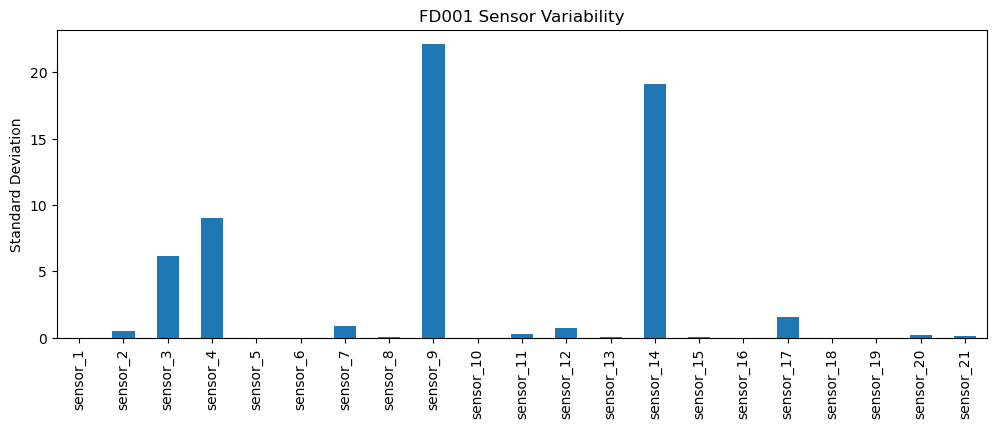

In [61]:
import matplotlib.pyplot as plt

# for CMAPSS it is important to remove any sensors that don't contribute to learning
# sensors that don't change can be removed for analysis 

sensor_cols = []
for i in range(1, 22):
    sensor_cols.append(f"sensor_{i}")

# Check missing values
print(train_df.isnull().sum())

# Examine sensor variability higher varaibility means change lower or zero means no change
sensor_std = train_df[sensor_cols].std()

# Visualize the sensor standard deviations
sensor_std.plot(kind = "bar", figsize=(12, 4))
plt.ylabel("Standard Deviation")
plt.title("FD001 Sensor Variability")
plt.show()

In [62]:
# only some of the sensors change so we use them for training the rest is not needed
selected_sensors = [
    "sensor_2", "sensor_3", "sensor_4",
    "sensor_7", "sensor_8", "sensor_9",
    "sensor_11", "sensor_12", "sensor_13",
    "sensor_14", "sensor_17", "sensor_20", "sensor_21"
]

from sklearn.model_selection import train_test_split

# now we can prepare the data by splitting into train and validation sets
# then normalize the data 

engine_ids = train_df["unit_id"].unique()

# 80% training , 20% validation 
# we need to split based on engine id because because rows from the same engine are
# highly correlated splitting by row would put some of an engine's cycles in
# training and others in validation, which would leak information 

train_ids, val_ids = train_test_split(engine_ids, test_size = 0.2, random_state=SPLIT_SEED, shuffle = True)

# Create the separate datasets
train_data = train_df[train_df["unit_id"].isin(train_ids)].copy()
val_data = train_df[train_df["unit_id"].isin(val_ids)].copy()

print("Training engines:", train_data["unit_id"].nunique())
print("Validation engines:", val_data["unit_id"].nunique())

Training engines: 80
Validation engines: 20


In [63]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# For most machine learning applciations we have to normalize our data
# use standard scaler for this which subtracts the mean and divides by the std

# use the selected engines only
train_data[selected_sensors] = scaler.fit_transform(train_data[selected_sensors])
val_data[selected_sensors] = scaler.transform(val_data[selected_sensors])

# Normalize test data with the standard scaler
test_data = test_df.copy()
test_data[selected_sensors] = scaler.transform(test_data[selected_sensors])

In [64]:
import numpy as np

# LSTM requires sequences to be fed not just a single input vector 
# The sequence window we will use is 50 cycles, so we create many of these sequences incrementing by 1, each with a RUL target of cycles 

def create_sequences(df, features, window_size):
    """
    This function generates a sequence for LSTM training, where each sequence belongs to one engine
    The label is the RUL at its final cycle

    Parameters:
    df: The data frame we will use for creating the sequence
    features: The selected features we want to retain
    window_size: How many cycles we will put into one sequence

    Returns:
    X, y: The feature and target matrix and vector for the sequences of one engine
    """

    # build the feature and targets empty arrays
    X, y = [], []

    # group by each engine type creating seperate manipulatble df for each engine

    for engine_id, engine in df.groupby("unit_id"):
        engine = engine.sort_values("cycle")

        # we need features for the X matrix and RUL cycles for the target y so we convert the needed values into numpy arrays
        sensor_data = engine[features].to_numpy(dtype = np.float32)
        rul_data = engine["RUL"].to_numpy(dtype = np.float32)

        # now make the sequences from the window size to the end of the data 
        # each sequence gets appended to X and y which are matrix and single values
        for end in range(window_size, len(engine) + 1):
            start = end - window_size

            # we want to retain a sequence window from start to end
            X.append(sensor_data[start:end])
            y.append(rul_data[end - 1])

    # use asarray to return a 3D tensor 
    return (np.asarray(X), np.asarray(y))

window_size = 50

# From online resources it seems that a common practice is to cap early-life RUL to avoid asking the model to distinguish very large RUL values from almost-healthy sensor readings
RUL_CAP = 125
if RUL_CAP is not None:
    train_data["RUL"] = train_data["RUL"].clip(upper = RUL_CAP)
    val_data["RUL"] = val_data["RUL"].clip(upper = RUL_CAP)

# create the sequence for training
X_train, y_train = create_sequences(train_data, selected_sensors, window_size)
X_val, y_val = create_sequences(val_data, selected_sensors, window_size)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

# since we train on sequences we also need to test on sequences
# use the same code but no feature
def create_test_sequences(df, features, window_size):
    X = []

    for engine_id, engine in df.groupby("unit_id"):
        engine = engine.sort_values("cycle")

        sensor_data = engine[features].to_numpy(dtype = np.float32)

        # Take last 50 cycles
        sequence = sensor_data[-window_size:]

        # If the the number of observations is less than 50 cycles then we will replace the remaing values with the first row 
        # this ensures that we maintain the correct window size
        if len(sequence) < window_size:
            padding = np.repeat(sequence[:1], window_size - len(sequence), axis = 0)
            sequence = np.vstack([padding, sequence])

        X.append(sequence)

    return np.asarray(X)


X_test = create_test_sequences(test_data, selected_sensors, window_size)

# Test labels correspond to the final cycle of each engine
y_test = rul_df["RUL"].to_numpy()

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (12641, 50, 13)
y_train: (12641,)
X_val: (3090, 50, 13)
y_val: (3090,)
X_test: (100, 50, 13)
y_test: (100,)


In [65]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Sklearn does not have a LSTM model however Pytorch does
# so we want to convery everything into pytorch tensors 

BATCH_SIZE = 64

# pair the data sets in pytorch frames
train_dataset = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train),)
val_dataset = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val),)

# we want to shuffle our training data set so that the model does not see the same pattern every epoch
train_loader = DataLoader(train_dataset, batch_size = BATCH_SIZE, shuffle = True)
val_loader = DataLoader(val_dataset, batch_size = BATCH_SIZE, shuffle = False)

print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))

Number of training batches: 198
Number of validation batches: 49


## LSTM Training and Evaluation

In [66]:
import random
import copy
from pathlib import Path
import torch.nn as nn

# now we build the LSTM model with pytorch 
# use a random seed 

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# First define the LSTM class

class RULLSTM(nn.Module):
    # we plan on using two hidden layers of size 64
    # dropout is set to 0.2 to help reduce over fitting setting some values to 0 when moving layers

    def __init__(self, input_size, hidden_size = 64, num_layers = 2, dropout = 0.2):
        super().__init__()

        # using the pytorch neural network LSTM library we define the LSTM 
        self.lstm = nn.LSTM(
            input_size = input_size,
            hidden_size = hidden_size,
            num_layers = num_layers,
            dropout = dropout if num_layers > 1 else 0.0,
            batch_first = True,
        )
        self.regressor = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        # x: (batch_size, window_size, number_of_sensors)
        outputs, (h_n, c_n) = self.lstm(x)
        last_hidden = h_n[-1]  # final time step of the top LSTM layer
        return self.regressor(last_hidden).squeeze(-1)


Using device: cpu


In [67]:
import copy
# Train using MSE; report RMSE in cycles for interpretability.
# Define the parameters 
# Early stopping will be implemented to help against overfitting so lets set Patience to 12 so that if it does not improve in 12 epochs we stop
def train_lstm(seed, epochs=80, patience=12):
    # Each call starts a new experiment
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # One CPU thread avoids the crash observed in the earlier check
    torch.set_num_threads(1)

    model = RULLSTM(input_size=len(selected_sensors)).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-5
    )

    # Recreate loaders after setting the seed
    generator = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    def run_epoch(loader, training=False):
        model.train(mode=training)
        squared_error_sum = 0.0
        count = 0

        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            if training:
                optimizer.zero_grad(set_to_none=True)

            with torch.set_grad_enabled(training):
                prediction = model(x_batch)
                loss = criterion(prediction, y_batch)

                if training:
                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(
                        model.parameters(), max_norm=1.0
                    )
                    optimizer.step()

            squared_error_sum += (
                (prediction.detach() - y_batch) ** 2
            ).sum().item()
            count += y_batch.numel()

        return (squared_error_sum / count) ** 0.5

    history = {"train_rmse": [], "val_rmse": []}
    best_val_rmse = float("inf")
    best_state = None
    best_epoch = 0
    stale_epochs = 0

    for epoch in range(1, epochs + 1):
        train_rmse = run_epoch(train_loader, training=True)
        val_rmse = run_epoch(val_loader, training=False)

        history["train_rmse"].append(train_rmse)
        history["val_rmse"].append(val_rmse)

        if val_rmse < best_val_rmse - 1e-4:
            best_val_rmse = val_rmse
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            stale_epochs = 0
        else:
            stale_epochs += 1

        if epoch == 1 or epoch % 5 == 0 or stale_epochs >= patience:
            print(
                f"Seed {seed}, epoch {epoch}: "
                f"train RMSE = {train_rmse:.3f}, "
                f"validation RMSE = {val_rmse:.3f} cycles"
            )

        if stale_epochs >= patience:
            print("Early stopping: validation RMSE did not improve.")
            break

    if best_state is None:
        raise RuntimeError("No successful epoch")

    model.load_state_dict(best_state)
    print(f"Best validation RMSE: {best_val_rmse:.3f} cycles, epoch {best_epoch}")

    return model, history, best_val_rmse, best_epoch

lstm_runs = {}
lstm_results = []

for seed in SEEDS:
    model, history, best_val_rmse, best_epoch = train_lstm(seed=seed)

    lstm_runs[seed] = {
        "model": model,
        "history": history,
        "best_val_rmse": best_val_rmse,
        "best_epoch": best_epoch
    }

    lstm_results.append({
        "seed": seed,
        "best_val_rmse": best_val_rmse,
        "best_epoch": best_epoch
    })

lstm_results_df = pd.DataFrame(lstm_results)
display(lstm_results_df)

Seed 2386, epoch 1: train RMSE = 69.411, validation RMSE = 44.600 cycles
Seed 2386, epoch 5: train RMSE = 10.781, validation RMSE = 11.128 cycles
Seed 2386, epoch 10: train RMSE = 8.925, validation RMSE = 12.378 cycles
Seed 2386, epoch 15: train RMSE = 6.734, validation RMSE = 12.644 cycles
Seed 2386, epoch 18: train RMSE = 6.025, validation RMSE = 12.444 cycles
Early stopping: validation RMSE did not improve.
Best validation RMSE: 11.092 cycles, epoch 6
Seed 7528, epoch 1: train RMSE = 68.679, validation RMSE = 38.875 cycles
Seed 7528, epoch 5: train RMSE = 10.859, validation RMSE = 11.945 cycles
Seed 7528, epoch 10: train RMSE = 8.780, validation RMSE = 13.141 cycles
Seed 7528, epoch 15: train RMSE = 6.908, validation RMSE = 12.771 cycles
Seed 7528, epoch 20: train RMSE = 5.414, validation RMSE = 13.697 cycles
Early stopping: validation RMSE did not improve.
Best validation RMSE: 11.415 cycles, epoch 8
Seed 7453, epoch 1: train RMSE = 69.759, validation RMSE = 43.971 cycles
Seed 7453

,seed,best_val_rmse,best_epoch
0,2386,11.092256,6
1,7528,11.415018,8
2,7453,11.388995,4
3,2863,10.863864,4
4,6439,10.670875,4


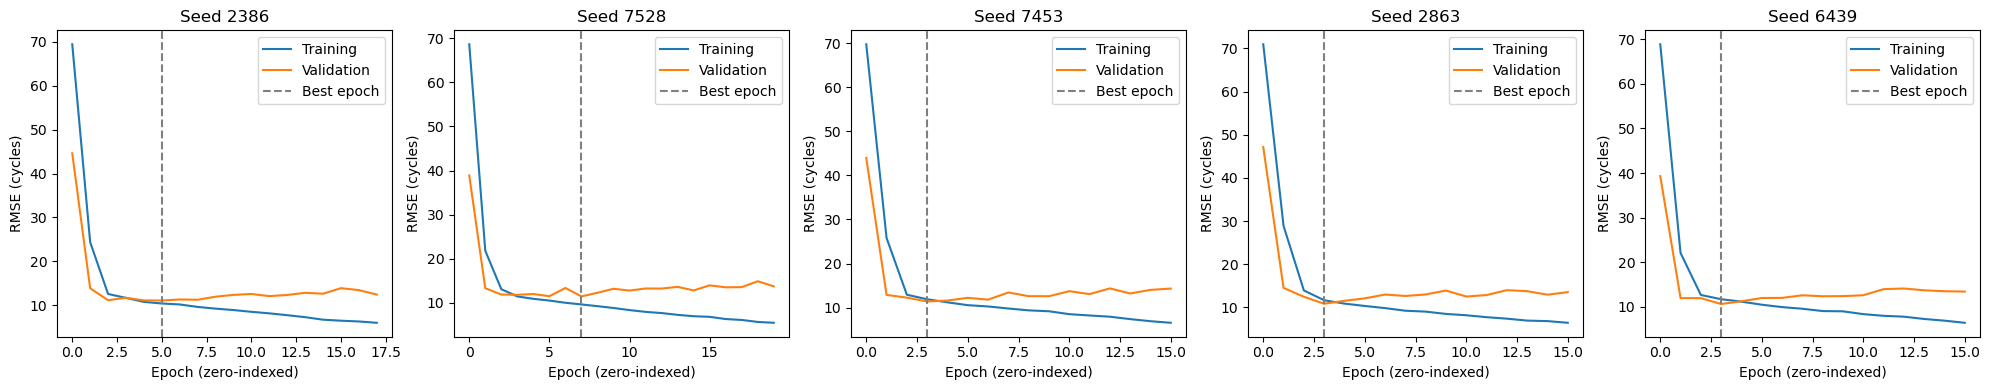

In [68]:
# plot the Epoch History and the RMSE
fig, axes = plt.subplots(1, len(SEEDS), figsize=(20, 4), squeeze=False)

for ax, seed in zip(axes[0], SEEDS):
    run = lstm_runs[seed]
    history = run["history"]

    ax.plot(history["train_rmse"], label="Training")
    ax.plot(history["val_rmse"], label="Validation")
    ax.axvline(
        run["best_epoch"] - 1,
        color="gray",
        linestyle="--",
        label="Best epoch"
    )

    ax.set_title(f"Seed {seed}")
    ax.set_xlabel("Epoch (zero-indexed)")
    ax.set_ylabel("RMSE (cycles)")
    ax.legend()

plt.tight_layout()
plt.show()

In [69]:
# Evaluate the model once after selecting the model by validation performance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def predict_in_batches(model, X, batch_size = 512):
    ''' 
    This function 
    '''
    model.eval()
    preds = []
    with torch.no_grad():
        for start in range(0, len(X), batch_size):
            batch = torch.from_numpy(X[start:start + batch_size]).to(device)
            preds.append(model(batch).cpu().numpy())
    return np.concatenate(preds)

def nasa_phm08_score(y_true, y_pred):
    ''' 
    This function defines the NASA penalty for the 2008 competition which penalizes late predictions more
    '''
    error = np.asarray(y_pred) - np.asarray(y_true)
    return float(np.where(error < 0, np.exp(-error / 13.0) - 1.0, np.exp(error / 10.0) - 1.0).sum())

# Negative RUL is not physically meaningful so we retain nonnegative predictions
evaluation_rows = []
prediction_tables = []

for seed in SEEDS:
    run = lstm_runs[seed]
    model = run["model"]

    y_pred = np.maximum(
        predict_in_batches(model, X_test), 0.0
    )

    evaluation_rows.append({
        "model": "LSTM",
        "seed": seed,
        "validation_rmse": run["best_val_rmse"],
        "best_epoch": run["best_epoch"],
        "test_rmse": np.sqrt(mean_squared_error(y_test, y_pred)),
        "test_mae": mean_absolute_error(y_test, y_pred),
        "test_r2": r2_score(y_test, y_pred),
        "nasa_score": nasa_phm08_score(y_test, y_pred)
    })

    prediction_tables.append(pd.DataFrame({
        "model": "LSTM",
        "seed": seed,
        "unit_id": sorted(test_data["unit_id"].unique()),
        "true_rul": y_test,
        "predicted_rul": y_pred,
        "error": y_pred - y_test
    }))

lstm_results_df = pd.DataFrame(evaluation_rows)
lstm_predictions_df = pd.concat(prediction_tables, ignore_index=True)

display(lstm_results_df)

summary = lstm_results_df[
    ["test_rmse", "test_mae", "test_r2", "nasa_score"]
].agg(["mean", "std"])

display(summary)

,model,seed,validation_rmse,best_epoch,test_rmse,test_mae,test_r2,nasa_score
0,LSTM,2386,11.092256,6,15.866434,11.913226,0.854220,422.593514
1,LSTM,7528,11.415018,8,14.873809,10.946020,0.871889,386.191215
2,LSTM,7453,11.388995,4,14.799121,10.582048,0.873173,343.369579
3,LSTM,2863,10.863864,4,15.883046,11.316965,0.853914,423.751055
4,LSTM,6439,10.670875,4,14.861505,10.894551,0.872101,364.573053


,test_rmse,test_mae,test_r2,nasa_score
mean,15.256783,11.130562,0.865059,388.095683
std,0.564856,0.509395,0.010047,35.421644


In [70]:
import json
import joblib

#recording experiment setting and results
output_dir = Path("artifacts/direction_1")
output_dir.mkdir(parents=True, exist_ok=True)

lstm_results_df.to_csv(output_dir / "lstm_metrics.csv", index=False)
lstm_predictions_df.to_csv(
    output_dir / "lstm_test_predictions.csv", index=False
)

experiment_info = {
    "dataset": "C-MAPSS FD001",
    "training_seeds": [int(seed) for seed in SEEDS],

    "rul_targets": {
        "training_and_validation_cap": RUL_CAP,
        "test_labels": "Official NASA RUL values, uncapped"
    },

    "inputs": {
        "window_length": window_size,
        "selected_sensors": selected_sensors,
        "training_windows": "Stride 1 within each engine; label at final cycle",
        "short_test_sequences": "Left-padded with the first observation"
    },

    "scaler": {
        "type": type(scaler).__name__,
        "fit_data": "Training engines only",
        "applied_to": "Training, validation, and test sensor readings",
        "saved_file": "fd001_scaler.joblib"
    },

    "engine_split": {
        "method": "Random split by engine ID",
        "split_seed": SPLIT_SEED,
        "validation_fraction": 0.2,
        "training_engine_ids": sorted(int(x) for x in train_ids),
        "validation_engine_ids": sorted(int(x) for x in val_ids),
        "same_split_for_all_training_seeds": True
    },

    "model_selection": {
        "criterion": "Lowest validation RMSE across all validation windows",
        "maximum_epochs": 80,
        "early_stopping_patience": 12,
        "minimum_improvement": 1e-4,
        "checkpoint": "Restore best validation checkpoint before testing"
    },

    "test_protocol": {
        "input": "Final available window from each official test engine",
        "predictions_per_engine": 1,
        "label_alignment": "NASA RUL file ordered by ascending test engine ID",
        "prediction_postprocessing": "Clamp negative predictions to zero",
        "metrics": ["RMSE", "MAE", "R2", "NASA asymmetric score"],
        "nasa_score_error": "predicted RUL minus true RUL",
        "nasa_score_divisors": {
            "underestimation": 13,
            "overestimation": 10
        },
        "summary": "Mean and sample standard deviation across training seeds"
    }
}

with open(output_dir / "experiment_info.json", "w") as file:
    json.dump(experiment_info, file, indent=4)

joblib.dump(scaler, output_dir / "fd001_scaler.joblib")

print("Saved experiment documentation and fitted scaler.")

Saved experiment documentation and fitted scaler.


## Random Forest Comparison:

In [71]:

from sklearn.ensemble import RandomForestRegressor

# Use the final cycle's sensor readings from each existing sequence
X_train_rf = X_train[:, -1, :]
X_val_rf = X_val[:, -1, :]
X_test_rf = X_test[:, -1, :]

print("Training:", X_train_rf.shape)
print("Validation:", X_val_rf.shape)
print("Testing:", X_test_rf.shape)

Training: (12641, 13)
Validation: (3090, 13)
Testing: (100, 13)


In [72]:
# Train one random forest per seed
rf_runs = {}
rf_validation_results = []

for seed in SEEDS:
    forest = RandomForestRegressor(
        n_estimators=200,
        random_state=seed,
        n_jobs=-1
    )

    forest.fit(X_train_rf, y_train)
    rf_runs[seed] = forest

    val_pred = np.maximum(forest.predict(X_val_rf), 0.0)
    val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

    rf_validation_results.append({
        "seed": seed,
        "validation_rmse": val_rmse
    })

    print(f"Seed {seed}: validation RMSE = {val_rmse:.3f} cycles")

rf_validation_df = pd.DataFrame(rf_validation_results)
display(rf_validation_df)

Seed 2386: validation RMSE = 17.877 cycles
Seed 7528: validation RMSE = 17.916 cycles
Seed 7453: validation RMSE = 17.913 cycles
Seed 2863: validation RMSE = 17.933 cycles
Seed 6439: validation RMSE = 17.971 cycles


,seed,validation_rmse
0,2386,17.877020
1,7528,17.915794
2,7453,17.912657
3,2863,17.932780
4,6439,17.971306


In [73]:
# Evaluate each random forest on the official test set
rf_evaluation_rows = []
rf_prediction_tables = []

for seed in SEEDS:
    forest = rf_runs[seed]
    test_pred = np.maximum(forest.predict(X_test_rf), 0.0)

    rf_evaluation_rows.append({
        "model": "Random forest",
        "seed": seed,
        "validation_rmse": rf_validation_df.loc[
            rf_validation_df["seed"] == seed, "validation_rmse"
        ].iloc[0],
        "best_epoch": np.nan,
        "test_rmse": np.sqrt(mean_squared_error(y_test, test_pred)),
        "test_mae": mean_absolute_error(y_test, test_pred),
        "test_r2": r2_score(y_test, test_pred),
        "nasa_score": nasa_phm08_score(y_test, test_pred)
    })

    rf_prediction_tables.append(pd.DataFrame({
        "model": "Random forest",
        "seed": seed,
        "unit_id": sorted(test_data["unit_id"].unique()),
        "true_rul": y_test,
        "predicted_rul": test_pred,
        "error": test_pred - y_test
    }))

rf_results_df = pd.DataFrame(rf_evaluation_rows)
rf_predictions_df = pd.concat(rf_prediction_tables, ignore_index=True)

display(rf_results_df)

rf_summary = rf_results_df[
    ["test_rmse", "test_mae", "test_r2", "nasa_score"]
].agg(["mean", "std"])

display(rf_summary)

,model,seed,validation_rmse,best_epoch,test_rmse,test_mae,test_r2,nasa_score
0,Random forest,2386,17.877020,NaN,17.541826,12.80175,0.821807,643.894083
1,Random forest,7528,17.915794,NaN,17.638939,12.91275,0.819829,612.324379
2,Random forest,7453,17.912657,NaN,17.359709,12.80285,0.825488,549.978709
3,Random forest,2863,17.932780,NaN,17.427738,12.70320,0.824118,598.712740
4,Random forest,6439,17.971306,NaN,17.621058,12.90390,0.820194,608.731835


,test_rmse,test_mae,test_r2,nasa_score
mean,17.517854,12.824890,0.822287,602.728349
std,0.121468,0.086301,0.002462,33.990414


In [74]:
# Compare LSTM and random forest across all seeds
comparison_df = pd.concat(
    [lstm_results_df, rf_results_df],
    ignore_index=True
)

comparison_summary = comparison_df.groupby("model")[
    ["test_rmse", "test_mae", "test_r2", "nasa_score"]
].agg(["mean", "std"])

display(comparison_df)
display(comparison_summary.round(3))

,model,seed,validation_rmse,best_epoch,test_rmse,test_mae,test_r2,nasa_score
0,LSTM,2386,11.092256,6.0,15.866434,11.913226,0.854220,422.593514
1,LSTM,7528,11.415018,8.0,14.873809,10.946020,0.871889,386.191215
2,LSTM,7453,11.388995,4.0,14.799121,10.582048,0.873173,343.369579
3,LSTM,2863,10.863864,4.0,15.883046,11.316965,0.853914,423.751055
4,LSTM,6439,10.670875,4.0,14.861505,10.894551,0.872101,364.573053
5,Random forest,2386,17.877020,NaN,17.541826,12.801750,0.821807,643.894083
6,Random forest,7528,17.915794,NaN,17.638939,12.912750,0.819829,612.324379
7,Random forest,7453,17.912657,NaN,17.359709,12.802850,0.825488,549.978709
8,Random forest,2863,17.932780,NaN,17.427738,12.703200,0.824118,598.712740
9,Random forest,6439,17.971306,NaN,17.621058,12.903900,0.820194,608.731835


test_rmse        test_mae        test_r2        nasa_score  \
                   mean    std     mean    std    mean    std       mean   
model                                                                      
LSTM             15.257  0.565   11.131  0.509   0.865  0.010    388.096   
Random forest    17.518  0.121   12.825  0.086   0.822  0.002    602.728   

                       
                  std  
model                  
LSTM           35.422  
Random forest  33.990